# Tobacco, Intoxicants and Household Health Spending — Uttarakhand, HCES 2023–24

Do households that spend on tobacco or intoxicants spend differently on health care? This notebook answers that with **survey-weighted** estimates from the processed household file (`../processed_data/hces_uttarakhand_master.csv`, 2,749 households).

**Weights.** `Multiplier` is the household survey weight; `Multiplier / 100` is the number of households each record represents. Shares and means below are weighted; nothing is a simple average.

**Definitions.**
- Tobacco household (`TC`): any monthly spending on tobacco
- Intoxicant household (`IC`): any monthly spending on alcohol or other intoxicants
- Health spending: hospitalisation spending (annual, converted to monthly) plus non-hospital medical spending, per household per month


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../processed_data/hces_uttarakhand_master.csv')
df['weight'] = df['Multiplier'] / 100                      # households represented
df['Health_Exp_Monthly'] = df['Hosp_Med_Exp_Monthly'] + df['NonHosp_Med_Exp_Monthly']
df['Health_Share'] = df['Health_Exp_Monthly'] / df['UMCE']  # share of monthly consumption
df['Sector_name'] = df['Sector'].map({1: 'Rural', 2: 'Urban'})
df['Social_group'] = df['Social_Group_of_HH_Head'].map({1: 'ST', 2: 'SC', 3: 'OBC', 9: 'General'})
df['Group'] = np.where(df['TC'] == 1, 'Tobacco', 'No tobacco')

def wmean(x, w):
    m = x.notna()
    return (x[m] * w[m]).sum() / w[m].sum()

print(f"Households in sample      : {len(df):,}")
print(f"Households represented    : {df['weight'].sum() / 1e5:.1f} lakh")
print(f"Rural / urban (weighted)  : {wmean(df['Sector'].eq(1).astype(float), df['weight']):.0%} rural")


Households in sample      : 2,749
Households represented    : 26.1 lakh
Rural / urban (weighted)  : 71% rural


## 1. How common is substance spending?

In [2]:
def prevalence(by=None):
    flags = {'Tobacco': 'TC', 'Intoxicants': 'IC', 'Either': 'TC_IC'}
    if by is None:
        return pd.Series({k: wmean(df[v].astype(float), df['weight']) for k, v in flags.items()}).to_frame('All households').T
    return df.groupby(by).apply(lambda g: pd.Series({k: wmean(g[v].astype(float), g['weight']) for k, v in flags.items()}))

overall = prevalence()
by_sector = prevalence('Sector_name')
by_quintile = prevalence('MPCE_Quintile').rename(index=lambda q: f'Q{int(q)}')
by_group = prevalence('Social_group').reindex(['ST', 'SC', 'OBC', 'General'])

(pd.concat([overall, by_sector, by_quintile, by_group]) * 100).round(1)


,Tobacco,Intoxicants,Either
All households,62.1,49.4,71.2
Rural,66.4,53.4,74.5
Urban,51.6,39.4,63.2
Q1,70.5,41.9,75.3
Q2,67.8,48.0,75.2
Q3,65.1,51.5,71.0
Q4,60.0,53.6,71.1
Q5,49.0,50.6,64.6
ST,68.7,60.0,83.1
SC,72.6,60.1,80.3


## 2. Hospitalisation and health spending: tobacco vs non-tobacco households

In [3]:
def compare(g):
    out = {}
    for name, sub in g.groupby('Group'):
        out[(name, 'Hospitalised (%)')] = 100 * wmean(sub['Hosp_Occurred'].astype(float), sub['weight'])
        out[(name, 'Health spend (₹/month)')] = wmean(sub['Health_Exp_Monthly'], sub['weight'])
        out[(name, 'Health share of budget (%)')] = 100 * wmean(sub['Health_Share'], sub['weight'])
    return pd.Series(out)

table = df.groupby('MPCE_Quintile').apply(compare).rename(index=lambda q: f'Q{int(q)}')
table.loc['Rural'] = compare(df[df['Sector'] == 1])
table.loc['Urban'] = compare(df[df['Sector'] == 2])
table.loc['All'] = compare(df)
table.round(1)


No tobacco                         \
              Hospitalised (%) Health spend (₹/month)   
MPCE_Quintile                                           
Q1                         8.8                  330.4   
Q2                         8.4                  600.2   
Q3                        11.4                  937.4   
Q4                        15.8                 1393.1   
Q5                        19.8                 2867.9   
Rural                     14.0                 1312.1   
Urban                     13.9                 1680.0   
All                       13.9                 1447.9   

                                                  Tobacco  \
              Health share of budget (%) Hospitalised (%)   
MPCE_Quintile                                               
Q1                                   2.5              7.4   
Q2                                   2.8             12.5   
Q3                                   4.2             15.3   
Q4                                   5.0             17.2   
Q5                                   7.4             21.8   
Rural                                5.1             16.1   
Urban                                4.3              9.6   
All                                  4.8             14.6   

                                                                 
              Health spend (₹/month) Health share of budget (%)  
MPCE_Quintile                                                    
Q1                             493.2                        2.3  
Q2                             708.0                        3.1  
Q3                             921.6                        3.8  
Q4                            1597.2                        5.6  
Q5                            2351.6                        6.7  
Rural                         1195.4                        4.5  
Urban                         1069.1                        3.2  
All                           1165.1                        4.2

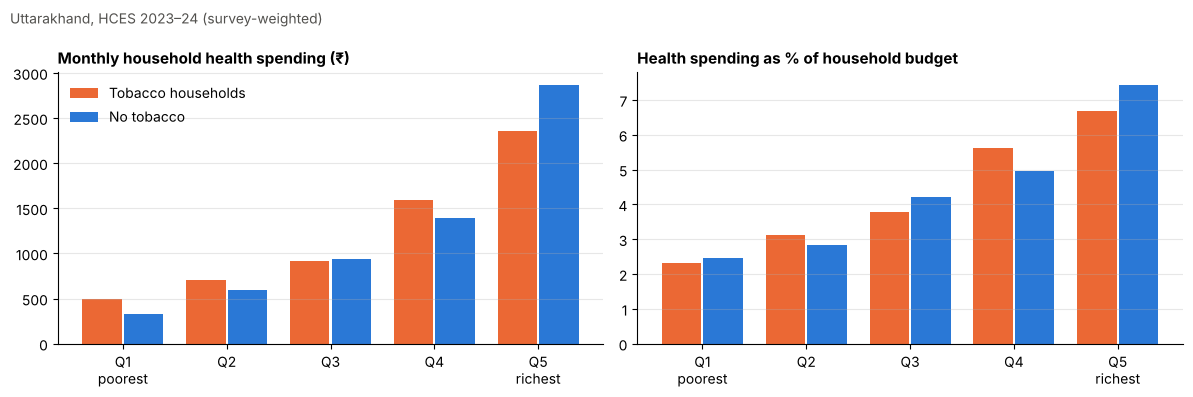

In [4]:
# Figure: health spending by consumption quintile, tobacco vs non-tobacco households
q = table.loc[[f'Q{i}' for i in range(1, 6)]]
x = np.arange(5)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in [
    (axes[0], 'Health spend (₹/month)', 'Monthly household health spending (₹)'),
    (axes[1], 'Health share of budget (%)', 'Health spending as % of household budget'),
]:
    ax.bar(x - 0.2, q[('Tobacco', metric)], 0.38, color='#eb6834', label='Tobacco households')
    ax.bar(x + 0.2, q[('No tobacco', metric)], 0.38, color='#2a78d6', label='No tobacco')
    ax.set_xticks(x, ['Q1\npoorest', 'Q2', 'Q3', 'Q4', 'Q5\nrichest'])
    ax.set_title(title, loc='left', fontweight='bold', fontsize=11)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=0.3)
axes[0].legend(frameon=False)
fig.suptitle('Uttarakhand, HCES 2023–24 (survey-weighted)', x=0.01, ha='left', fontsize=10, color='#52514e')
plt.tight_layout()
plt.savefig('../assets/health_spending_by_quintile.png', dpi=150, bbox_inches='tight')
plt.show()


## 3. How much do substance households spend on tobacco and intoxicants?

In [5]:
users = df[df['TC_IC'] == 1].copy()
users['Substance_Exp'] = users['Tobacco_Exp_Monthly'] + users['Intox_Exp_Monthly']
summary = users.groupby('MPCE_Quintile').apply(lambda g: pd.Series({
    'Substance spend (₹/month)': wmean(g['Substance_Exp'], g['weight']),
    'Health spend (₹/month)':    wmean(g['Health_Exp_Monthly'], g['weight']),
    'Substance ÷ health spend':  wmean(g['Substance_Exp'], g['weight']) / wmean(g['Health_Exp_Monthly'], g['weight']),
})).rename(index=lambda q: f'Q{int(q)}')
summary.round(2)


,Substance spend (₹/month),Health spend (₹/month),Substance ÷ health spend
MPCE_Quintile,,,
Q1,861.93,490.13,1.76
Q2,1070.20,679.42,1.58
Q3,1433.43,927.34,1.55
Q4,1592.55,1570.89,1.01
Q5,2056.13,2420.16,0.85


## 4. Reading the results

These are **descriptive, survey-weighted comparisons**. They show where tobacco and health spending co-occur, but they do not by themselves prove that substance spending *causes* lower health spending: tobacco households also differ in caste, sector and household composition. Establishing a causal "crowding-out" effect needs a design that adjusts for those differences (for example matching or regression with controls) and survey-appropriate standard errors.
